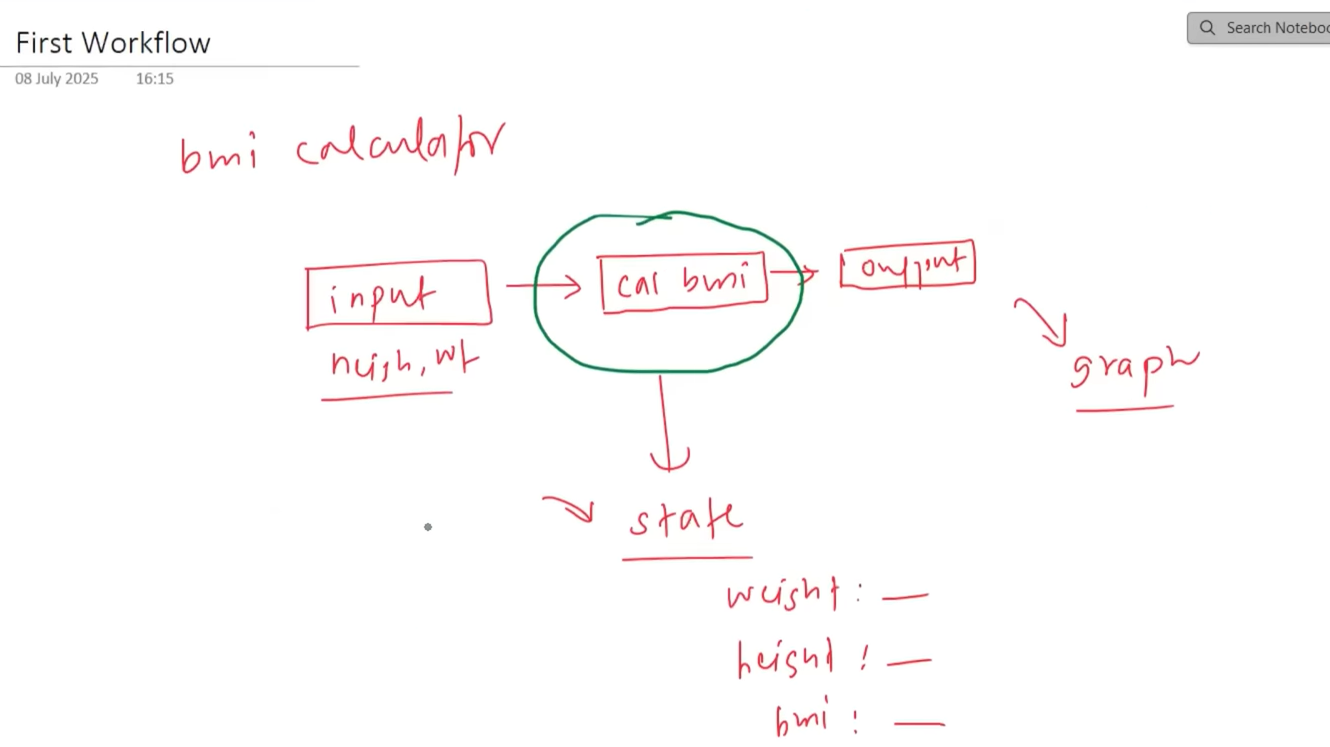

In [8]:
from langgraph.graph import StateGraph, START , END
from typing import TypedDict

In [13]:
class BMIState(TypedDict):
    weight_kg : float 
    height_m : float
    bmi : float
    category : str

In [5]:

def calaculate_bmi(state : BMIState) -> BMIState:

    weight = state['weight_kg']
    height = state['height_m']

    bmi = weight / (height ** 2 )

    state['bmi'] = round(bmi , 2)

    return state
    

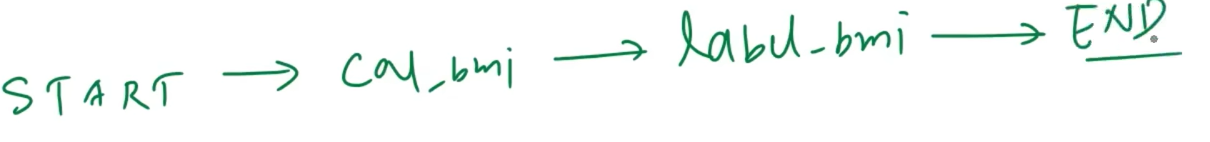

In [14]:
def label_bmi(state: BMIState) -> BMIState:

    bmi = state['bmi']

    if bmi < 18.5:
        state["category"] = "Underweight"
    elif 18.5 <= bmi < 25:
        state["category"] = "Normal"
    elif 25 <= bmi < 30:
        state["category"] = "Overweight"
    else:
        state["category"] = "Obese"

    return state


In [15]:
# define a graph 
graph = StateGraph(BMIState)

# define the nodes 
graph.add_node("calculate_bmi" , calaculate_bmi)
graph.add_node('label_bmi' , label_bmi)

# define the edges 
graph.add_edge(START , 'calculate_bmi')
graph.add_edge('calculate_bmi' , 'label_bmi')
graph.add_edge('label_bmi' , END)

# compile the graph
workflow = graph.compile() # compiled graph object milega

In [17]:
intial_state = {'weight_kg' : 80 , 'height_m' : 1.83}
final_state =workflow.invoke(intial_state)

print(final_state)

{'weight_kg': 80, 'height_m': 1.83, 'bmi': 23.89, 'category': 'Normal'}


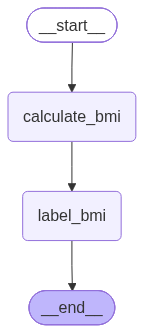

In [16]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())